# Bulk differential expression

## Intro

`edge_rs` is edgeR's quasi-likelihood pipeline and limma-voom for Python,
without R. The numerics are a Rust port of both packages, checked against
edgeR 4.8.2 and limma 3.66.0. The Python layer is thin on purpose: counts go
in as a NumPy array, results come out as polars frames, and every function
is named after the R function it reproduces. If you have run
`glmQLFit()` or `voom()` before, there is nothing new to learn here.

The flow is the one from the edgeR and limma user guides:

```
filter_by_expr()       # drop genes too low to test
calc_norm_factors()    # TMM
  -> glm_ql_fit()   -> glm_ql_ftest()  -> top_tags()    # edgeR QL
  -> voom_lm_fit()  -> ebayes()        -> top_table()   # limma-voom
```

Two conventions to keep in mind throughout. Counts are **genes x samples**,
as in R. And a design can be a plain NumPy matrix or a polars frame; with the
frame, its column names become coefficient names you can test by name.

In [1]:
import gzip
import timeit
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import edge_rs

## The data

The mouse mammary gland data from
[Fu, et al.](https://doi.org/10.1038/ncb3117), the same data the edgeR
quasi-likelihood workflow of
[Chen, Lun and Smyth](https://doi.org/10.12688/f1000research.8987.2) is
built on. Basal and luminal cells, sorted from virgin, pregnant and
lactating mice, two replicates each: twelve samples, six groups. GEO carries
the gene counts as a supplementary file, and the series matrix tells us which
sample is which.

In [2]:
GEO = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE60nnn/GSE60450"


def fetch(url: str) -> bytes:
    return gzip.decompress(urlopen(url).read())


raw = pl.read_csv(
    fetch(f"{GEO}/suppl/GSE60450_Lactation-GenewiseCounts.txt.gz"), separator="\t"
)

raw.head()

EntrezGeneID,Length,MCL1-DG_BC2CTUACXX_ACTTGA_L002_R1,MCL1-DH_BC2CTUACXX_CAGATC_L002_R1,MCL1-DI_BC2CTUACXX_ACAGTG_L002_R1,MCL1-DJ_BC2CTUACXX_CGATGT_L002_R1,MCL1-DK_BC2CTUACXX_TTAGGC_L002_R1,MCL1-DL_BC2CTUACXX_ATCACG_L002_R1,MCL1-LA_BC2CTUACXX_GATCAG_L001_R1,MCL1-LB_BC2CTUACXX_TGACCA_L001_R1,MCL1-LC_BC2CTUACXX_GCCAAT_L001_R1,MCL1-LD_BC2CTUACXX_GGCTAC_L001_R1,MCL1-LE_BC2CTUACXX_TAGCTT_L001_R1,MCL1-LF_BC2CTUACXX_CTTGTA_L001_R1
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
497097,3634,438,300,65,237,354,287,0,0,0,0,0,0
100503874,3259,1,0,1,1,0,4,0,0,0,0,0,0
100038431,1634,0,0,0,0,0,0,0,0,0,0,0,0
19888,9747,1,1,0,0,0,0,10,3,10,2,0,0
20671,3130,106,182,82,105,43,82,16,25,18,8,3,10


The sample annotation sits in the series matrix as tab-separated `!Sample_*`
lines. We need the title, which carries cell type and stage, and the sample
name, which matches the count columns.

In [3]:
series = fetch(f"{GEO}/matrix/GSE60450_series_matrix.txt.gz").decode().splitlines()


def sample_field(key: str) -> list[str]:
    line = next(x for x in series if x.startswith(key))
    return [v.strip('"') for v in line.split("\t")[1:]]


stage = {"virgin": "virgin", "18.5 dP": "pregnant", "2 dL": "lactating"}

samples = (
    pl.DataFrame(
        {
            "title": sample_field("!Sample_title"),
            "sample": sample_field("!Sample_description"),
        }
    )
    .with_columns(
        pl.col("sample").str.strip_prefix("Sample name: "),
        cell_type=pl.col("title").str.extract(r"^(\w+) "),
        stage=pl.col("title").str.extract(r"^\w+ (.+) #\d$").replace_strict(stage),
    )
    .with_columns(
        group=pl.col("cell_type").str.slice(0, 1) + "_" + pl.col("stage"),
    )
    .sort("sample")
)

samples

title,sample,cell_type,stage,group
str,str,str,str,str
"""Basal virgin #1""","""MCL1-DG""","""Basal""","""virgin""","""B_virgin"""
"""Basal virgin #2""","""MCL1-DH""","""Basal""","""virgin""","""B_virgin"""
"""Basal 18.5 dP #1""","""MCL1-DI""","""Basal""","""pregnant""","""B_pregnant"""
"""Basal 18.5 dP #2""","""MCL1-DJ""","""Basal""","""pregnant""","""B_pregnant"""
"""Basal 2 dL #1""","""MCL1-DK""","""Basal""","""lactating""","""B_lactating"""
…,…,…,…,…
"""Luminal virgin #2""","""MCL1-LB""","""Luminal""","""virgin""","""L_virgin"""
"""Luminal 18.5 dP #1""","""MCL1-LC""","""Luminal""","""pregnant""","""L_pregnant"""
"""Luminal 18.5 dP #2""","""MCL1-LD""","""Luminal""","""pregnant""","""L_pregnant"""


Line the count columns up with the sample table (the column names carry the
sample name plus flow cell, barcode and lane), and pull the counts out as a
genes x samples array.

In [4]:
count_cols = [c for c in raw.columns if c.startswith("MCL1")]
by_sample = {c.split("_")[0]: c for c in count_cols}

counts = raw.select([by_sample[s] for s in samples["sample"]]).to_numpy()
gene_ids = raw["EntrezGeneID"]

counts.shape

(27179, 12)

Integers are fine. Everything is converted to `float64` on the way into Rust,
and the orientation does not need to be C-contiguous either; a transposed
view works just as well.

## Filtering

`filter_by_expr()` is edgeR's `filterByExpr()`: keep a gene if it reaches a
minimum count-per-million in enough samples to make up the smallest group.
Pass the grouping (any sequence of labels, a NumPy array or a polars Series)
or a design.

In [5]:
keep = edge_rs.filter_by_expr(counts, group=samples["group"])

print(f"{keep.sum()} of {keep.size} genes kept")

15969 of 27179 genes kept


## Normalisation

TMM normalisation factors next, on the kept genes. The one subtlety is the
library size. edgeR's `keep.lib.sizes = TRUE` default keeps the library sizes
of the full count matrix after filtering, so we pass the unfiltered column
sums explicitly. Leave `lib_size` out and you get the column sums of
whatever you hand in, which after a filter is not the same thing.

In [6]:
lib_size = counts.sum(axis=0)
kept = counts[keep]
kept_ids = gene_ids.filter(keep)

norm_factors = edge_rs.calc_norm_factors(kept, lib_size=lib_size)

samples = samples.with_columns(
    lib_size=pl.Series(lib_size), norm_factors=pl.Series(norm_factors)
)

samples.select("sample", "group", "lib_size", "norm_factors")

sample,group,lib_size,norm_factors
str,str,i64,f64
"""MCL1-DG""","""B_virgin""",23227641,1.238375
"""MCL1-DH""","""B_virgin""",21777891,1.213552
"""MCL1-DI""","""B_pregnant""",24100765,1.124759
"""MCL1-DJ""","""B_pregnant""",22665371,1.071164
"""MCL1-DK""","""B_lactating""",21529331,1.036301
…,…,…,…
"""MCL1-LB""","""L_virgin""",21708152,1.364858
"""MCL1-LC""","""L_pregnant""",22241607,1.004067
"""MCL1-LD""","""L_pregnant""",21988240,0.9227


`method` takes `"TMM"`, `"TMMwsp"`, `"RLE"`, `"upperquartile"` and `"none"`,
as in edgeR.

### With a `DgeList`

If carrying `lib_size` around by hand sounds like a bug waiting to happen,
`make_dgelist()` bundles counts, library sizes, normalisation factors and
annotation into a frozen record, edgeR's `DGEList` minus the S4. Subsetting
genes keeps the library sizes of the full matrix, and every function that
takes counts takes a `DgeList` instead and reads both from it.

In [7]:
dge = edge_rs.make_dgelist(
    counts, genes=pl.DataFrame({"gene_id": gene_ids}), samples=samples
)
dge = edge_rs.calc_norm_factors(
    dge[edge_rs.filter_by_expr(dge, group=samples["group"])]
)

print(dge.shape, np.array_equal(dge.norm_factors, norm_factors))

(15969, 12) True


Same genes, same factors. `glm_ql_fit(dge, design)` and
`voom_lm_fit(dge, design)` work the same way; pass
`feature_ids=dge.genes["gene_id"]` to `top_tags()` or `top_table()`. The rest
of this vignette sticks with plain arrays, to show what goes where.

## A first look

Before testing anything, check what separates the samples. Log-CPM via
`cpm()`, then a PCA on the 500 most variable genes with plain NumPy.

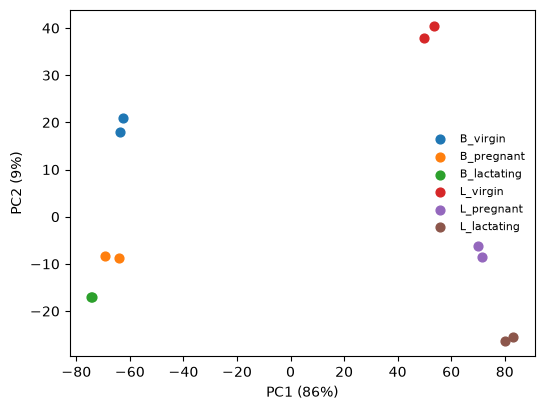

In [8]:
log_cpm = edge_rs.cpm(
    kept, lib_size=lib_size, norm_factors=norm_factors, log=True, prior_count=2.0
)

top = np.argsort(log_cpm.var(axis=1))[-500:]
x = log_cpm[top] - log_cpm[top].mean(axis=1, keepdims=True)
u, s, vt = np.linalg.svd(x, full_matrices=False)
var_explained = s**2 / (s**2).sum()

fig, ax = plt.subplots(figsize=(6, 4.5))
for g in samples["group"].unique(maintain_order=True):
    idx = (samples["group"] == g).to_numpy()
    ax.scatter(vt[0, idx] * s[0], vt[1, idx] * s[1], label=g, s=40)
ax.set_xlabel(f"PC1 ({var_explained[0]:.0%})")
ax.set_ylabel(f"PC2 ({var_explained[1]:.0%})")
ax.legend(frameon=False, fontsize=8)
plt.show()

PC1 is cell type (86% of the variance), PC2 the developmental stage, and the
replicates sit on top of each other. Clean data.

## The design

One coefficient per group, no intercept, which makes the contrasts easy to
read. A polars frame keeps the column names; a NumPy matrix works as well,
but then coefficients go by position only.

In [9]:
groups = sorted(samples["group"].unique())

design = pl.DataFrame({g: (samples["group"] == g).cast(pl.Float64) for g in groups})

design

B_lactating,B_pregnant,B_virgin,L_lactating,L_pregnant,L_virgin
f64,f64,f64,f64,f64,f64
0.0,0.0,1.0,0.0,0.0,0.0
0.0,0.0,1.0,0.0,0.0,0.0
0.0,1.0,0.0,0.0,0.0,0.0
0.0,1.0,0.0,0.0,0.0,0.0
1.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…
0.0,0.0,0.0,0.0,0.0,1.0
0.0,0.0,0.0,0.0,1.0,0.0
0.0,0.0,0.0,0.0,1.0,0.0


`make_contrasts()` is limma's `makeContrasts()`: name to expression over the
design columns. The F1000 workflow asks three questions, so let's ask them
too. Pregnant versus lactating in basal cells, the same in luminal cells,
and whether the two differ.

In [10]:
contrasts = edge_rs.make_contrasts(
    {
        "B_PvsL": "B_pregnant - B_lactating",
        "L_PvsL": "L_pregnant - L_lactating",
        "BvsL_PvsL": "(B_pregnant - B_lactating) - (L_pregnant - L_lactating)",
    },
    design,
)

contrasts.with_columns(level=pl.Series(design.columns))

B_PvsL,L_PvsL,BvsL_PvsL,level
f64,f64,f64,str
-1.0,0.0,-1.0,"""B_lactating"""
1.0,0.0,1.0,"""B_pregnant"""
0.0,0.0,0.0,"""B_virgin"""
0.0,-1.0,1.0,"""L_lactating"""
0.0,1.0,-1.0,"""L_pregnant"""
0.0,0.0,0.0,"""L_virgin"""


One column per contrast, one row per design column. That frame goes straight
into both the edgeR and the limma tests.

## edgeR quasi-likelihood

`glm_ql_fit()` fits the negative binomial GLM per gene and squeezes the
quasi-likelihood dispersions towards a trend, as edgeR 4's `glmQLFit()` does.
No separate `estimateDisp()` step: since edgeR 4 the QL fit estimates what it
needs itself. `legacy=True` gives you the old route with the trended
dispersion from `estimateDisp()` first.

In [11]:
fit = edge_rs.glm_ql_fit(
    kept, design, lib_size=lib_size, norm_factors=norm_factors, robust=True
)

fit

QLFit(n_genes=15969, n_samples=12, n_coef=6)

The fit is an opaque object holding what the test needs, with the bits you
would want to look at exposed as arrays: coefficients, the prior degrees of
freedom, the squeezed dispersions and their trend.

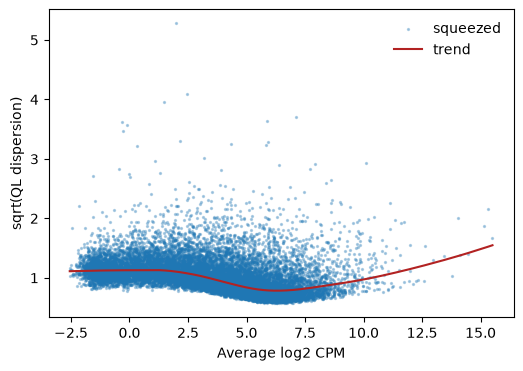

Prior df: median 6.4


In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(fit.ave_log_cpm, np.sqrt(fit.s2_post), s=2, alpha=0.3, label="squeezed")
order = np.argsort(fit.ave_log_cpm)
ax.plot(
    fit.ave_log_cpm[order],
    np.sqrt(np.broadcast_to(fit.s2_prior, fit.ave_log_cpm.shape))[order],
    color="firebrick",
    label="trend",
)
ax.set_xlabel("Average log2 CPM")
ax.set_ylabel("sqrt(QL dispersion)")
ax.legend(frameon=False)
plt.show()

print(f"Prior df: median {np.median(fit.df_prior):.1f}")

`glm_ql_ftest()` takes a coefficient (by name or position) or a contrast,
and `top_tags()` turns the test into a table. Pass `feature_ids` and the
table carries your gene ids, otherwise you get the 0-based row index.

In [13]:
ql = edge_rs.glm_ql_ftest(fit, contrast=contrasts.select("B_PvsL"))

ql_res = edge_rs.top_tags(ql, feature_ids=kept_ids)

ql_res.head(10)

feature_id,log_fc,log_cpm,f_stat,p_value,fdr
i64,f64,f64,f64,f64,f64
211577,-5.148684,2.744613,473.178464,7.5541e-13,1.2063e-8
140474,7.173677,6.052649,336.724496,4.6133e-11,2.7969e-7
12992,-6.08614,10.183969,433.935808,5.2544e-11,2.7969e-7
24117,1.819773,6.757919,284.950951,1.4184e-10,5.1839e-7
21953,-5.755317,3.8552,360.078239,1.6231e-10,5.1839e-7
226101,-2.323442,6.443503,312.987564,3.7151e-10,8.6280e-7
381290,-2.144934,6.140342,311.481059,3.8401e-10,8.6280e-7
12740,5.320132,9.866835,301.6747,4.6292e-10,8.6280e-7
14621,4.539477,5.523529,235.341376,4.8627e-10,8.6280e-7


The FDR is Benjamini-Hochberg over every gene, so thinning the table with
`n` or `p_cutoff` does not change it.

In [14]:
ql_res.select(
    up=((pl.col("fdr") < 0.05) & (pl.col("log_fc") > 0)).sum(),
    down=((pl.col("fdr") < 0.05) & (pl.col("log_fc") < 0)).sum(),
)

up,down
u32,u32
2814,2608


And the MD plot.

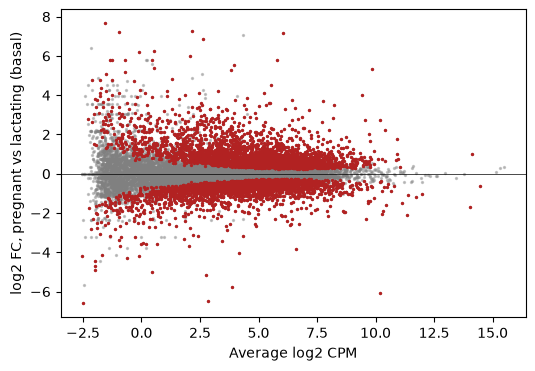

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
sig = (ql_res["fdr"] < 0.05).to_numpy()
ax.scatter(ql_res["log_cpm"], ql_res["log_fc"], s=2, c="grey", alpha=0.4)
ax.scatter(
    ql_res["log_cpm"].filter(sig), ql_res["log_fc"].filter(sig), s=2, c="firebrick"
)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("Average log2 CPM")
ax.set_ylabel("log2 FC, pregnant vs lactating (basal)")
plt.show()

Hand `glm_ql_ftest()` several coefficients or several contrasts and you get
one F-test across all of them: edgeR's ANOVA-like test. Is there any
difference between the three luminal groups? With a group-means design that
is two contrasts against a common baseline, not the three luminal columns:
dropping those would test whether luminal expression is zero.

In [16]:
luminal = edge_rs.make_contrasts(
    {
        "PvsV": "L_pregnant - L_virgin",
        "LvsV": "L_lactating - L_virgin",
    },
    design,
)

anova = edge_rs.glm_ql_ftest(fit, contrast=luminal)

edge_rs.top_tags(anova, feature_ids=kept_ids).select(
    df_test=pl.lit(anova.df_test),
    sig=(pl.col("fdr") < 0.05).sum(),
)

df_test,sig
f64,u32
2.0,11291


Two degrees of freedom, one F and one p-value per gene. The `log_fc` of a
test like this is the first contrast only, as in edgeR's first `logFC`
column, so read the effect sizes off the individual contrasts.

## limma-voom

Same data, same design, limma's route. `voom_lm_fit()` is edgeR's
`voomLmFit()`: voom's precision weights and the weighted linear model in one
step, with structural zeros (a group that is all zero for a gene) handled
properly. Then `contrasts_fit()` and `ebayes()`, as in limma.

In [17]:
vfit = edge_rs.voom_lm_fit(kept, design, lib_size=lib_size, norm_factors=norm_factors)
vfit = edge_rs.ebayes(edge_rs.contrasts_fit(vfit, contrasts))

vfit

LinearFit(n_genes=15969, n_coef=3, ebayes=true)

Each step returns a new `LinearFit`, so the fit before `ebayes()` is still
there if you want it. `top_table()` is `topTable()`, including the
confidence interval on the fold change.

In [18]:
voom_res = edge_rs.top_table(vfit, coef="B_PvsL", feature_ids=kept_ids, confint=True)

voom_res.head(10)

feature_id,log_fc,ci_lower,ci_upper,ave_expr,t,p_value,adj_p_value,b
i64,f64,f64,f64,f64,f64,f64,f64,f64
24117,1.819628,1.622991,2.016265,2.975067,20.16753,1.3141e-10,0.000001,14.749628
381290,-2.143846,-2.388306,-1.899387,3.943589,-19.112645,2.4555e-10,0.000001,14.186241
78896,2.806805,2.475895,3.137716,3.036042,18.485707,3.6163e-10,0.000001,13.806064
226101,-2.329922,-2.605805,-2.054039,6.223047,-18.405612,3.8030e-10,0.000001,13.728242
231830,2.252881,1.981555,2.524206,4.76012,18.095975,4.6290e-10,0.000001,13.510118
16012,-2.896219,-3.237986,-2.554452,1.977971,-18.468679,3.6551e-10,0.000001,13.404762
16669,-2.312519,-2.610482,-2.014556,8.741415,-16.914433,1.0099e-9,0.000002,12.852784
14620,3.59989,3.1433,4.05648,3.524803,17.182946,8.4216e-10,0.000002,12.780176
55987,-1.515905,-1.713186,-1.318624,2.834035,-16.746417,1.1330e-9,0.000002,12.754862


Want the voom mean-variance trend? `voom()` on its own returns the log-CPM,
the weights and the trend.

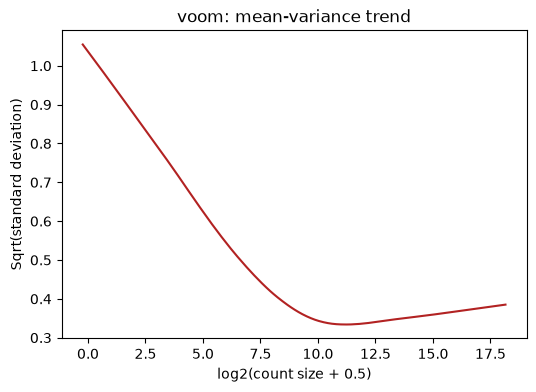

In [19]:
v = edge_rs.voom(kept, design, lib_size=lib_size, norm_factors=norm_factors)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(v.trend_x, v.trend_y, color="firebrick")
ax.set_xlabel("log2(count size + 0.5)")
ax.set_ylabel("Sqrt(standard deviation)")
ax.set_title("voom: mean-variance trend")
plt.show()

`v.e` and `v.weights` go into `lm_fit()` for limma's classic two-step route,
which is also how you would run limma-trend on `cpm(..., log=True)` with
`ebayes(fit, trend=True)`.

### edgeR and limma side by side

Two models, one question. They should agree on the big picture and differ
at the margins.

In [20]:
both = ql_res.join(voom_res, on="feature_id", suffix="_voom")

both.select(
    cor_log_fc=pl.corr("log_fc", "log_fc_voom"),
    sig_ql=(pl.col("fdr") < 0.05).sum(),
    sig_voom=(pl.col("adj_p_value") < 0.05).sum(),
    sig_both=((pl.col("fdr") < 0.05) & (pl.col("adj_p_value") < 0.05)).sum(),
)

cor_log_fc,sig_ql,sig_voom,sig_both
f64,u32,u32,u32
0.973565,5422,5279,5034


Fold changes correlate at 0.97 and over nine in ten genes called by one are
called by the other. The rest sit near the threshold, where a negative
binomial and a weighted linear model on log-CPM are allowed to disagree.

## One-liners

Most of the time you want the whole chain on a count matrix and nothing in
between. `run_edger_ql()` and `run_limma_voom()` do filter, TMM, fit, test
and table in one go, on the **unfiltered** counts. The defaults match the
steps above, so the answers do too.

In [21]:
quick_ql = edge_rs.run_edger_ql(
    counts,
    design,
    feature_ids=gene_ids,
    contrast=contrasts.select("B_PvsL"),
    robust=True,
)
quick_voom = edge_rs.run_limma_voom(
    counts, design, feature_ids=gene_ids, contrast=contrasts.select("B_PvsL")
)

check = quick_ql.join(ql_res, on="feature_id", suffix="_steps").join(
    quick_voom.join(voom_res, on="feature_id", suffix="_steps"),
    on="feature_id",
    suffix="_voom",
)

check.select(
    n_genes=pl.len(),
    max_diff_ql=(pl.col("p_value") - pl.col("p_value_steps")).abs().max(),
    max_diff_voom=(pl.col("p_value_voom") - pl.col("p_value_steps_voom")).abs().max(),
)

n_genes,max_diff_ql,max_diff_voom
u32,f64,f64
15969,0.0,0.0


The one-liners return the genes in input order (`sort_by="none"`), which is
what you want when you join the result onto something else. Sort it
yourself when you want a ranking.

## Speed

Twelve samples and 16k genes after filtering is small, and it shows.

In [22]:
for name, f in {
    "edgeR QL": lambda: edge_rs.run_edger_ql(
        counts, design, contrast=contrasts.select("B_PvsL")
    ),
    "limma-voom": lambda: edge_rs.run_limma_voom(
        counts, design, contrast=contrasts.select("B_PvsL")
    ),
}.items():
    t = min(timeit.repeat(f, number=1, repeat=5))
    print(f"{name}: {t * 1000:.0f} ms")

edgeR QL: 89 ms


limma-voom: 72 ms


## What is not there (yet)

The Rust crate has more than the bindings expose so far. Not in Python yet:
the exact test, `glmFit()` / `glmLRT()` / `glmTreat()`, `diffSpliceDGE()`,
limma's moderated F-test across several coefficients (`topTableF()`),
`duplicateCorrelation()` and sample weights. NEBULA lives in
[bixverse](https://github.com/GregorLueg/bixverse-rs), where the single cell
data is.

For pseudobulk from single cell data, see the
[pseudobulk vignette](pseudobulk.ipynb).